<a href="https://colab.research.google.com/github/mujtaba-mohiyuddin/ucb-traffic-sign-recognition/blob/main/20261010_UCB_Assignment_Week23_RandomForest_Heart_Disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 23 Practice Problem 1: Random Forest Classification on Heart Disease

**Dataset:** UCI Heart Disease (Cleveland), 303 patients, 13 features. **Target:** 0 = no disease, 1 = disease present.

**Goal:** Build a Random Forest classifier, show the benefit of an ensemble (bagging) over a single Decision Tree, tune its key settings with cross-validation, and interpret feature importances.

## 1. Load and Prepare

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# The raw file has no header row, so we assign column names manually.
# Missing values are stored as '?', so we tell pandas to treat '?' as NaN.
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

df = pd.read_csv(url, header=None, names=columns, na_values="?")

print("Shape:", df.shape)
df.head()

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Handle missing values
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Only a handful of rows are affected (in 'ca' and 'thal'), so dropping them is a safe, simple choice
df = df.dropna().reset_index(drop=True)
print("\nShape after dropping missing rows:", df.shape)

Missing values per column:
ca      4
thal    2
dtype: int64

Shape after dropping missing rows: (297, 14)


In [14]:
# Binarize the target: original values 1-4 are different severities of disease -> all become 1
df["target"] = (df["target"] > 0).astype(int)
print(df["target"].value_counts())

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTrain:", X_train.shape, "Test:", X_test.shape)

target
0    160
1    137
Name: count, dtype: int64

Train: (237, 13) Test: (60, 13)


## 2. Baseline: Single Decision Tree

In [5]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

dt_test_acc = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Test Accuracy: {dt_test_acc:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=["No Disease", "Disease"]))

Decision Tree Test Accuracy: 0.7833

Confusion Matrix:
[[27  9]
 [ 4 20]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.75      0.81        36
     Disease       0.69      0.83      0.75        24

    accuracy                           0.78        60
   macro avg       0.78      0.79      0.78        60
weighted avg       0.80      0.78      0.79        60



## 3. Random Forest (n_estimators=100)

In [6]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_test_acc = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Test Accuracy: {rf_test_acc:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=["No Disease", "Disease"]))

Random Forest Test Accuracy: 0.8833

Confusion Matrix:
[[32  4]
 [ 3 21]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.91      0.89      0.90        36
     Disease       0.84      0.88      0.86        24

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60



In [7]:
# Side-by-side comparison, including training accuracy to expose overfitting
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Train Accuracy": [accuracy_score(y_train, dt.predict(X_train)), accuracy_score(y_train, rf.predict(X_train))],
    "Test Accuracy": [dt_test_acc, rf_test_acc]
})
comparison["Gap (Train - Test)"] = comparison["Train Accuracy"] - comparison["Test Accuracy"]
comparison

,Model,Train Accuracy,Test Accuracy,Gap (Train - Test)
0,Decision Tree,1.0,0.783333,0.216667
1,Random Forest,1.0,0.883333,0.116667


**Which performs better, and why?**

Check the table above for your actual numbers. Typically the Random Forest wins on test accuracy. The reason:

- A single, fully grown decision tree fits the training data almost perfectly (train accuracy ~100%), meaning it has memorized quirks of the training set. This is **high variance**: change the training data slightly and the tree changes a lot.
- A Random Forest builds many trees, each on a different random sample of the rows (**bootstrap sampling / bagging**) and considering only a random subset of features at each split. The trees make different mistakes, and **averaging their votes cancels out much of the noise**, which lowers variance and generalizes better to unseen patients.

Note: with only ~60 test patients, one or two predictions change accuracy by 1-3 points, so small differences between models should be read with caution.

## 4. Tune `n_estimators`
5-fold cross-validation accuracy on the **training set only** (the test set stays untouched until the very end).

In [8]:
n_estimators_list = [10, 50, 100, 200, 300, 500]
cv_results = []

for n in n_estimators_list:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_results.append({"n_estimators": n, "cv_accuracy": scores.mean(), "cv_std": scores.std()})
    print(f"n_estimators={n:>3}: CV accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})")

cv_df = pd.DataFrame(cv_results)
best_n = int(cv_df.loc[cv_df["cv_accuracy"].idxmax(), "n_estimators"])
print(f"\nBest n_estimators: {best_n}")

n_estimators= 10: CV accuracy = 0.7930 (+/- 0.0265)
n_estimators= 50: CV accuracy = 0.7973 (+/- 0.0264)
n_estimators=100: CV accuracy = 0.8017 (+/- 0.0548)
n_estimators=200: CV accuracy = 0.8015 (+/- 0.0502)
n_estimators=300: CV accuracy = 0.7972 (+/- 0.0540)
n_estimators=500: CV accuracy = 0.7972 (+/- 0.0633)

Best n_estimators: 100


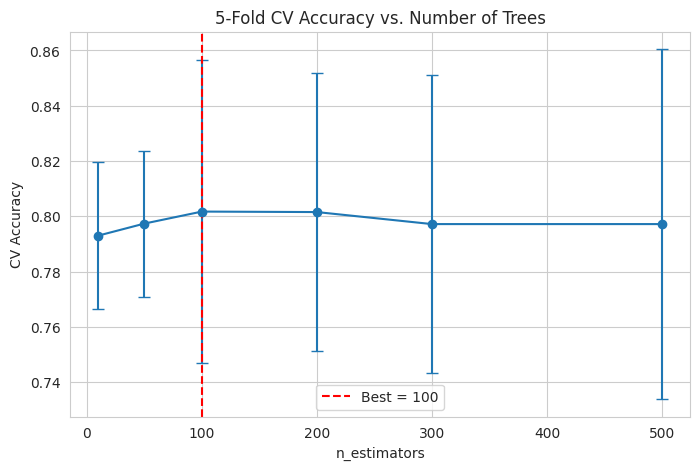

In [9]:
plt.figure(figsize=(8,5))
plt.errorbar(cv_df["n_estimators"], cv_df["cv_accuracy"], yerr=cv_df["cv_std"], marker="o", capsize=4)
plt.axvline(best_n, color="red", linestyle="--", label=f"Best = {best_n}")
plt.title("5-Fold CV Accuracy vs. Number of Trees")
plt.xlabel("n_estimators")
plt.ylabel("CV Accuracy")
plt.legend()
plt.show()

## 5. Tune `max_depth` (using the best `n_estimators`)

In [10]:
max_depth_list = [3, 5, 7, 10, 15, None]
depth_results = []

for d in max_depth_list:
    model = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=42, n_jobs=-1)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    depth_results.append({"max_depth": "None" if d is None else d, "max_depth_value": d,
                          "cv_accuracy": scores.mean(), "cv_std": scores.std()})
    print(f"max_depth={str(d):>4}: CV accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})")

depth_df = pd.DataFrame(depth_results)
best_row = depth_df.loc[depth_df["cv_accuracy"].idxmax()]
best_depth = best_row["max_depth_value"]
best_depth = None if pd.isna(best_depth) else int(best_depth)
print(f"\nBest combination: n_estimators={best_n}, max_depth={best_depth}")

max_depth=   3: CV accuracy = 0.8353 (+/- 0.0320)
max_depth=   5: CV accuracy = 0.8057 (+/- 0.0422)
max_depth=   7: CV accuracy = 0.8057 (+/- 0.0325)
max_depth=  10: CV accuracy = 0.7931 (+/- 0.0516)
max_depth=  15: CV accuracy = 0.8017 (+/- 0.0548)
max_depth=None: CV accuracy = 0.8017 (+/- 0.0548)

Best combination: n_estimators=100, max_depth=3


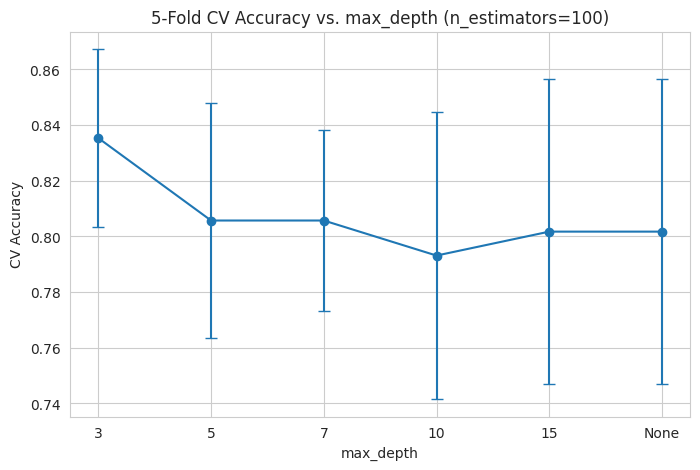

In [11]:
plt.figure(figsize=(8,5))
plt.errorbar(depth_df["max_depth"].astype(str), depth_df["cv_accuracy"], yerr=depth_df["cv_std"], marker="o", capsize=4)
plt.title(f"5-Fold CV Accuracy vs. max_depth (n_estimators={best_n})")
plt.xlabel("max_depth")
plt.ylabel("CV Accuracy")
plt.show()

In [12]:
# Final model: best combination, trained on the full training set, scored ONCE on the test set
final_rf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=42, n_jobs=-1)
final_rf.fit(X_train, y_train)
y_pred_final = final_rf.predict(X_test)

final_test_acc = accuracy_score(y_test, y_pred_final)
print(f"Final Tuned Random Forest Test Accuracy: {final_test_acc:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, target_names=["No Disease", "Disease"]))

summary = pd.DataFrame({
    "Model": ["Decision Tree (default)", "Random Forest (100 trees, default depth)", "Random Forest (tuned)"],
    "Test Accuracy": [dt_test_acc, rf_test_acc, final_test_acc]
})
summary

Final Tuned Random Forest Test Accuracy: 0.8667

Confusion Matrix:
[[33  3]
 [ 5 19]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.92      0.89        36
     Disease       0.86      0.79      0.83        24

    accuracy                           0.87        60
   macro avg       0.87      0.85      0.86        60
weighted avg       0.87      0.87      0.87        60



,Model,Test Accuracy
0,Decision Tree (default),0.783333
1,"Random Forest (100 trees, default depth)",0.883333
2,Random Forest (tuned),0.866667


## 6. Interpret Feature Importances
The goal of the exercise also asks us to interpret which features drive the predictions.

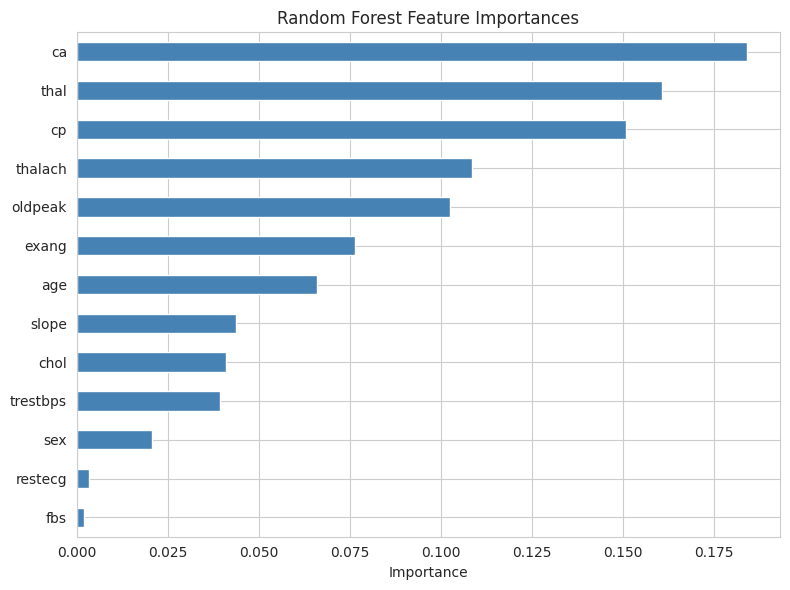

ca          0.1841
thal        0.1608
cp          0.1511
thalach     0.1087
oldpeak     0.1027
exang       0.0766
age         0.0661
slope       0.0439
chol        0.0410
trestbps    0.0393
sex         0.0207
restecg     0.0032
fbs         0.0019
dtype: float64


In [13]:
importances = pd.Series(final_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8,6))
importances.plot(kind="barh", color="steelblue")
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(4))

**How to read this:** importance shows how much each feature reduces impurity across all trees in the forest (higher = used more often for useful splits). Features describing chest pain type (`cp`), thalassemia result (`thal`), number of major vessels (`ca`), max heart rate (`thalach`), and ST depression (`oldpeak`) commonly rank near the top on this dataset, but confirm against your own chart.

Caveats worth mentioning: importance shows *association with the prediction*, not medical causation, and impurity-based importance can favor features with many distinct values (like `chol` or `oldpeak`).

In [16]:
##OOB Score

rf_oob = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                 oob_score=True, random_state=42)
rf_oob.fit(X_train, y_train)

print(f'OOB Accuracy:  {rf_oob.oob_score_:.4f}')
print(f'Test Accuracy: {rf_oob.score(X_test, y_test):.4f}')
print('\nThe OOB score is an unbiased estimate of generalization error computed from')
print('out-of-bag samples (data not used to train each individual tree).')

OOB Accuracy:  0.8017
Test Accuracy: 0.8667

The OOB score is an unbiased estimate of generalization error computed from
out-of-bag samples (data not used to train each individual tree).
